In [1]:
# 1. Autentificarea Kaggle prin Colab Secrets
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("rmn")

print("Tokenul a fost încărcat din Secrets.")

Tokenul a fost încărcat din Secrets.


In [ ]:
# 2. Descărcarea și dezarhivarea datasetului
%pip -q install kaggle

!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

# 2. O dezarhivăm automat într-un folder pe serverul Google Colab
import zipfile
with zipfile.ZipFile('brain-tumor-mri-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('baza_de_date_tumori')

print("Baza de date a fost descărcată și dezarhivată cu succes!")

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:01<00:00, 99.6MB/s]

Baza de date a fost descărcată și dezarhivată cu succes!


--- STATISTICA BAZEI DE DATE ---
Clasa 'glioma': 1400 poze de Antrenament | 400 poze de Testare
Clasa 'meningioma': 1400 poze de Antrenament | 400 poze de Testare
Clasa 'notumor': 1400 poze de Antrenament | 400 poze de Testare
Clasa 'pituitary': 1400 poze de Antrenament | 400 poze de Testare

Total poze Training: 5600
Total poze Testing: 1600


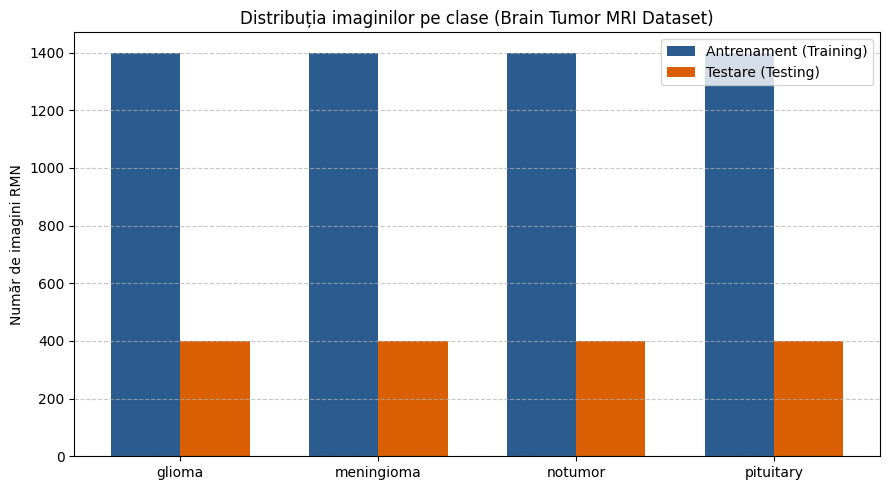

In [3]:
# 3. Distribuția imaginilor pe clase
import os
import matplotlib.pyplot as plt
import numpy as np

cale_training = os.path.join('baza_de_date_tumori', 'Training')
cale_testing = os.path.join('baza_de_date_tumori', 'Testing')

clase = sorted(os.listdir(cale_training))
numar_train = []
numar_test = []

print("--- STATISTICA BAZEI DE DATE ---")
for clasa in clase:
    n_tr = len(os.listdir(os.path.join(cale_training, clasa)))
    n_te = len(os.listdir(os.path.join(cale_testing, clasa)))
    numar_train.append(n_tr)
    numar_test.append(n_te)
    print(f"Clasa '{clasa}': {n_tr} poze de Antrenament | {n_te} poze de Testare")

print(f"\nTotal poze Training: {sum(numar_train)}")
print(f"Total poze Testing: {sum(numar_test)}")

# Generăm graficul distribuției imaginilor pe clase

x = np.arange(len(clase))
latime = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - latime/2, numar_train, latime, label='Antrenament (Training)', color='#2b5c8f')
ax.bar(x + latime/2, numar_test, latime, label='Testare (Testing)', color='#d95f02')

ax.set_ylabel('Număr de imagini RMN')
ax.set_title('Distribuția imaginilor pe clase (Brain Tumor MRI Dataset)')
ax.set_xticks(x)
ax.set_xticklabels(clase)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('distributie_clase_licenta.png', dpi=300)
plt.show()

Maparea claselor în cifre pentru rețeaua neuronală: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Număr pachete (batches) de antrenament: 175 (câte 32 poze/pachet)
Dimensiunea matematică a unui pachet (Batch Shape): torch.Size([32, 3, 224, 224])



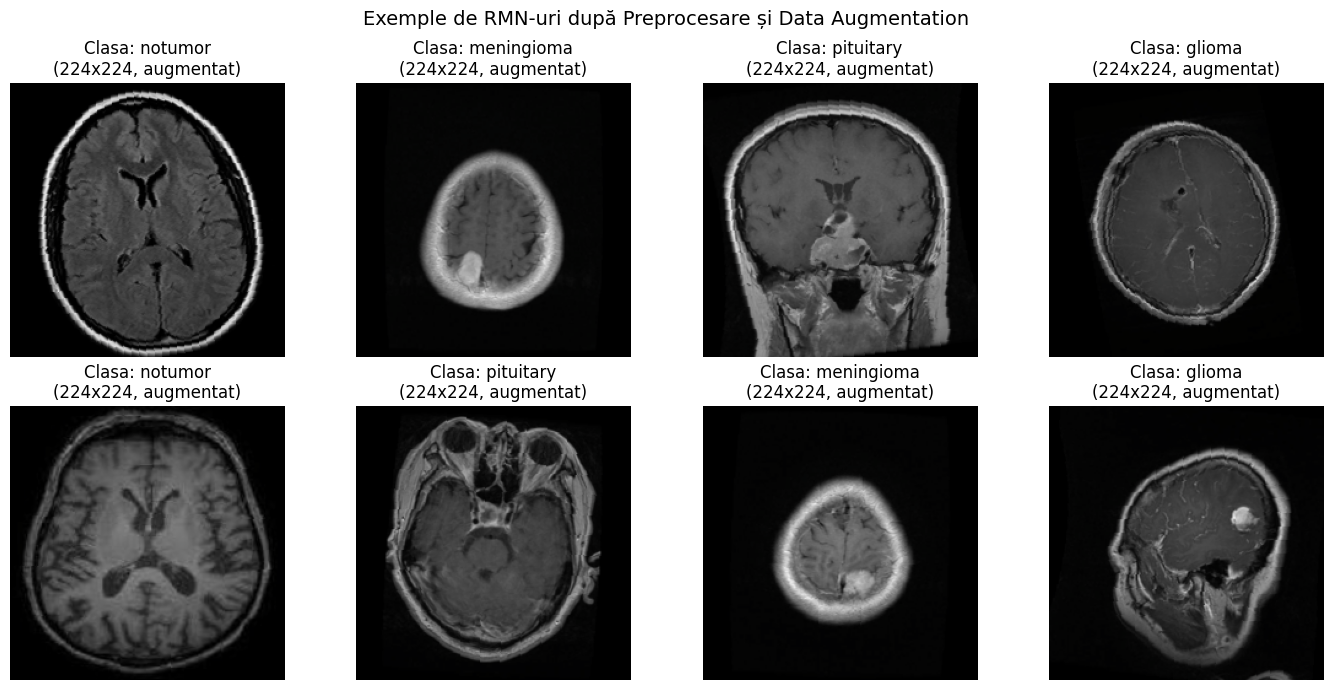

In [ ]:
# 4. Preprocesarea imaginilor și încărcarea în batchuri
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Regulile de transformare pentru ANTRENAMENT (cu Data Augmentation)
transformari_train = transforms.Compose([
    transforms.Resize((224, 224)),             # Aducem toate RMN-urile la 224x224 pixeli
    transforms.RandomHorizontalFlip(p=0.5),    # Oglindire orizontală (50% șanse)
    transforms.RandomRotation(degrees=10),     # Rotire ușoară între -10 și +10 grade
    transforms.ToTensor(),                     # Transformare în matrice numerică (Tensor)
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Regulile pentru TESTARE (fără rotiri, doar redimensionare și normalizare)
transformari_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Încărcăm seturile de date și creăm benzile rulante (DataLoaders) cu pachete de 32 poze
dataset_train = datasets.ImageFolder(root=cale_training, transform=transformari_train)
dataset_test = datasets.ImageFolder(root=cale_testing, transform=transformari_test)

loader_train = DataLoader(dataset_train, batch_size=32, shuffle=True)
loader_test = DataLoader(dataset_test, batch_size=32, shuffle=False)

print(f"Maparea claselor în cifre pentru rețeaua neuronală: {dataset_train.class_to_idx}")
print(f"Număr pachete (batches) de antrenament: {len(loader_train)} (câte 32 poze/pachet)")

# 4. Scoatem un pachet de probă și afișăm 8 RMN-uri gata preprocesate
imagini_batch, etichete_batch = next(iter(loader_train))
print(f"Dimensiunea matematică a unui pachet (Batch Shape): {imagini_batch.shape}\n")

def denormalizeaza(tensor_img):
    img = tensor_img.numpy().transpose((1, 2, 0))
    img = np.array([0.229, 0.224, 0.225]) * img + np.array([0.485, 0.456, 0.406])
    return np.clip(img, 0, 1)

nume_clase = dataset_train.classes
plt.figure(figsize=(14, 7))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(denormalizeaza(imagini_batch[i]))
    plt.title(f"Clasa: {nume_clase[etichete_batch[i]]}\n(224x224, augmentat)")
    plt.axis('off')

plt.suptitle("Exemple de RMN-uri după Preprocesare și Data Augmentation", fontsize=14)
plt.tight_layout()
plt.savefig('rmn_preprocesate_licenta.png', dpi=300)
plt.show()

In [ ]:
# 5. Verificarea directoarelor datasetului
import os

# Verificăm ce foldere există în interiorul directorului dezarhivat
cale_folder = 'baza_de_date_tumori'
print("Conținutul folderului:", os.listdir(cale_folder))


Conținutul folderului: ['Training', 'Testing']


Clasele de tumori disponibile în dataset: ['glioma', 'pituitary', 'notumor', 'meningioma']


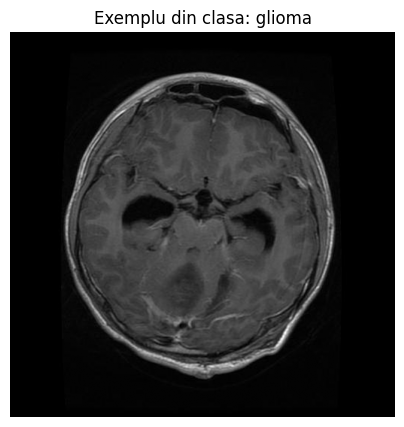

In [ ]:
# 6. Afișarea unei imagini RMN originale
import os
import matplotlib.pyplot as plt
from PIL import Image

# 1. Vedem clasele (categoriile) de tumori din setul de antrenament
cale_training = os.path.join('baza_de_date_tumori', 'Training')
clase = os.listdir(cale_training)
print(f"Clasele de tumori disponibile în dataset: {clase}")

# 2. Alegem prima clasă și luăm o imagine din ea
prima_clasa = clase[0]
cale_clasa = os.path.join(cale_training, prima_clasa)
nume_poza = os.listdir(cale_clasa)[0]
cale_completa_poza = os.path.join(cale_clasa, nume_poza)

# 3. Deschidem și afișăm imaginea RMN 2D
imagine = Image.open(cale_completa_poza)
plt.figure(figsize=(5, 5))
plt.imshow(imagine, cmap='gray')
plt.title(f"Exemplu din clasa: {prima_clasa}")
plt.axis('off')
plt.show()

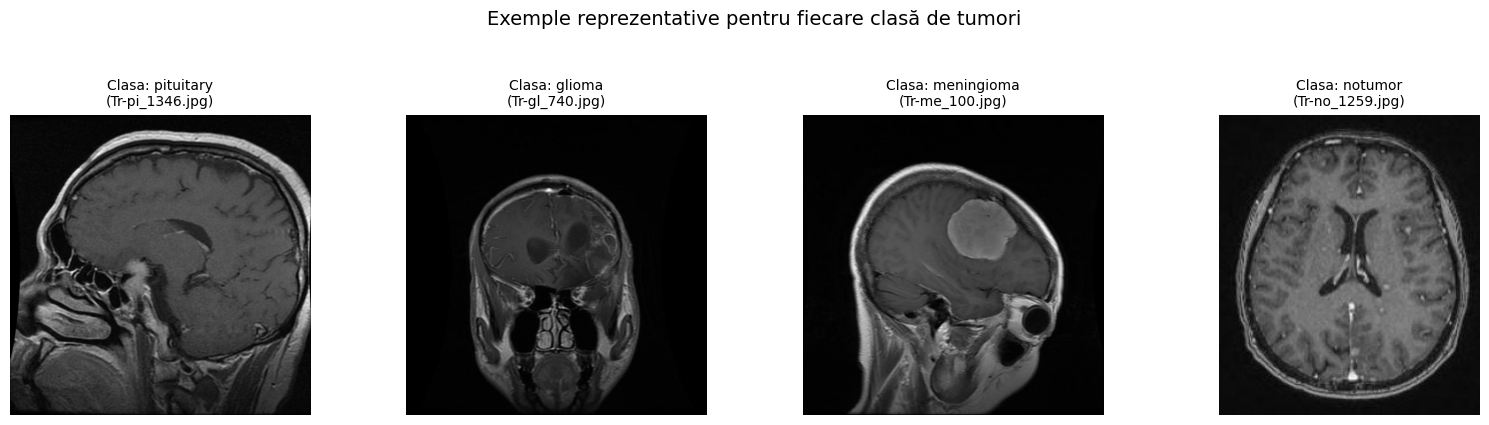

In [ ]:
# 7. Afișarea unui exemplu din fiecare clasă
import os
import matplotlib.pyplot as plt
from PIL import Image

# Definim clasele identificate anterior
clase_tumori = ['pituitary', 'glioma', 'meningioma', 'notumor']
cale_training = os.path.join('baza_de_date_tumori', 'Training')

# Pregătim figura cu 4 sub-grafice pe un singur rând
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, clasa in enumerate(clase_tumori):
    cale_clasa = os.path.join(cale_training, clasa)

    # Selectăm prima imagine din folderul clasei respective
    imagini_clasa = os.listdir(cale_clasa)
    nume_imagine = imagini_clasa[0]
    cale_completa = os.path.join(cale_clasa, nume_imagine)

    # Deschidem și afișăm imaginea
    img = Image.open(cale_completa)
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Clasa: {clasa}\n({nume_imagine})", fontsize=10)
    axes[i].axis('off')

plt.suptitle("Exemple reprezentative pentru fiecare clasă de tumori", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

In [ ]:
# 8. Verificarea numărului de imagini din fiecare set
import os

cale_baza = 'baza_de_date_tumori'
seturi = ['Training', 'Testing']

for set_nume in seturi:
    print(f"--- Setul de {set_nume} ---")
    cale_set = os.path.join(cale_baza, set_nume)
    clase = sorted(os.listdir(cale_set))

    total_imagini = 0
    for clasa in clase:
        cale_clasa = os.path.join(cale_set, clasa)
        nr_imagini = len(os.listdir(cale_clasa))
        print(f"  Clasa '{clasa}': {nr_imagini} imagini")
        total_imagini += nr_imagini

    print(f"Total imagini în {set_nume}: {total_imagini}\n")

--- Setul de Training ---
  Clasa 'glioma': 1400 imagini
  Clasa 'meningioma': 1400 imagini
  Clasa 'notumor': 1400 imagini
  Clasa 'pituitary': 1400 imagini
Total imagini în Training: 5600

--- Setul de Testing ---
  Clasa 'glioma': 400 imagini
  Clasa 'meningioma': 400 imagini
  Clasa 'notumor': 400 imagini
  Clasa 'pituitary': 400 imagini
Total imagini în Testing: 1600



In [4]:
# 9. Verificarea imaginilor necitibile

from pathlib import Path
from PIL import Image

baza = Path("baza_de_date_tumori")
extensii = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp", ".ppm", ".pgm"
}

for set_nume in ["Training", "Testing"]:
    if not (baza / set_nume).is_dir():
        raise FileNotFoundError(
            "Rulează mai întâi descărcarea și dezarhivarea datasetului."
        )

imagini = sorted(
    cale
    for set_nume in ["Training", "Testing"]
    for cale in (baza / set_nume).rglob("*")
    if cale.is_file() and cale.suffix.lower() in extensii
)

if not imagini:
    raise RuntimeError("Nu au fost găsite imagini.")

probleme = []

for cale in imagini:
    try:
        with Image.open(cale) as imagine:
            imagine.load()
    except (OSError, ValueError, SyntaxError) as eroare:
        probleme.append(
            (str(cale.relative_to(baza)), str(eroare))
        )

print("Imagini verificate:", len(imagini))
print("Imagini cu probleme:", len(probleme))

for cale, mesaj in probleme[:10]:
    print(cale, "->", mesaj)

Imagini verificate: 7200
Imagini cu probleme: 0


In [5]:
# 10. Verificarea duplicatelor exacte

import hashlib
from collections import defaultdict

grupuri = defaultdict(list)

for cale in imagini:
    amprenta = hashlib.sha256(cale.read_bytes()).hexdigest()
    grupuri[amprenta].append(cale.relative_to(baza))

duplicate = [
    grup for grup in grupuri.values()
    if len(grup) > 1
]

intre_seturi = [
    grup for grup in duplicate
    if len({cale.parts[0] for cale in grup}) > 1
]

etichete_diferite = [
    grup for grup in duplicate
    if len({cale.parts[1] for cale in grup}) > 1
]

print("Grupuri de duplicate exacte:", len(duplicate))
print(
    "Fișiere implicate în duplicate:",
    sum(len(grup) for grup in duplicate)
)
print(
    "Grupuri comune Training și Testing:",
    len(intre_seturi)
)
print(
    "Grupuri cu etichete diferite:",
    len(etichete_diferite)
)

for numar, grup in enumerate(duplicate[:10], start=1):
    print("\nGrupul", numar)
    for cale in grup:
        print(" ", cale)

Grupuri de duplicate exacte: 153
Fișiere implicate în duplicate: 340
Grupuri comune Training și Testing: 0
Grupuri cu etichete diferite: 0

Grupul 1
  Testing/glioma/Te-gl_129.jpg
  Testing/glioma/Te-gl_303.jpg

Grupul 2
  Testing/glioma/Te-gl_140.jpg
  Testing/glioma/Te-gl_238.jpg

Grupul 3
  Testing/glioma/Te-gl_143.jpg
  Testing/glioma/Te-gl_72.jpg

Grupul 4
  Testing/glioma/Te-gl_144.jpg
  Testing/glioma/Te-gl_59.jpg

Grupul 5
  Testing/glioma/Te-gl_166.jpg
  Testing/glioma/Te-gl_278.jpg

Grupul 6
  Testing/glioma/Te-gl_170.jpg
  Testing/glioma/Te-gl_178.jpg

Grupul 7
  Testing/glioma/Te-gl_171.jpg
  Testing/glioma/Te-gl_228.jpg

Grupul 8
  Testing/glioma/Te-gl_177.jpg
  Testing/glioma/Te-gl_36.jpg

Grupul 9
  Testing/glioma/Te-gl_204.jpg
  Testing/glioma/Te-gl_259.jpg

Grupul 10
  Testing/glioma/Te-gl_212.jpg
  Testing/glioma/Te-gl_272.jpg
  Testing/glioma/Te-gl_338.jpg


In [6]:
# 11. Distribuția duplicatelor pe seturi și clase

import pandas as pd

if intre_seturi or etichete_diferite:
    raise RuntimeError(
        "Analizează întâi grupurile comune între seturi sau clase."
    )

randuri = []

for set_nume in ["Training", "Testing"]:
    for clasa in ["glioma", "meningioma", "notumor", "pituitary"]:
        grupuri_clasa = [
            grup for grup in grupuri.values()
            if grup[0].parts[0] == set_nume
            and grup[0].parts[1] == clasa
        ]

        initiale = sum(len(grup) for grup in grupuri_clasa)
        distincte = len(grupuri_clasa)

        randuri.append({
            "Set": set_nume,
            "Clasa": clasa,
            "Fișiere inițiale": initiale,
            "Distincte SHA-256": distincte,
            "Copii suplimentare": initiale - distincte
        })

tabel_duplicate = pd.DataFrame(randuri)
display(tabel_duplicate)

print(
    "Total fișiere inițiale:",
    int(tabel_duplicate["Fișiere inițiale"].sum())
)
print(
    "Total conținuturi distincte:",
    int(tabel_duplicate["Distincte SHA-256"].sum())
)
print(
    "Total copii suplimentare:",
    int(tabel_duplicate["Copii suplimentare"].sum())
)

,Set,Clasa,Fișiere inițiale,Distincte SHA-256,Copii suplimentare
0,Training,glioma,1400,1400,0
1,Training,meningioma,1400,1386,14
2,Training,notumor,1400,1281,119
3,Training,pituitary,1400,1362,38
4,Testing,glioma,400,386,14
5,Testing,meningioma,400,398,2
6,Testing,notumor,400,400,0
7,Testing,pituitary,400,400,0


Total fișiere inițiale: 7200
Total conținuturi distincte: 7013
Total copii suplimentare: 187


In [7]:
# 12. Crearea listelor de fișiere pentru experimente

from pathlib import Path
import pandas as pd

if probleme:
    raise RuntimeError(
        "Există imagini necitibile. Analizează celula 9 înainte de a continua."
    )

if intre_seturi or etichete_diferite:
    raise RuntimeError(
        "Există duplicate între seturi sau clase. Analizează aceste grupuri."
    )

randuri = []

for amprenta, copii in grupuri.items():
    for cale in copii:
        randuri.append({
            "cale_relativa": cale.as_posix(),
            "set_original": cale.parts[0],
            "clasa": cale.parts[1],
            "sha256": amprenta
        })

inventar_fisiere = pd.DataFrame(randuri).sort_values("cale_relativa")

training_initial = inventar_fisiere[
    inventar_fisiere["set_original"] == "Training"
].copy()

testing_original = inventar_fisiere[
    inventar_fisiere["set_original"] == "Testing"
].copy()

training_distinct = training_initial.drop_duplicates(
    subset="sha256", keep="first"
).copy()

testing_distinct = testing_original.drop_duplicates(
    subset="sha256", keep="first"
).copy()

rapoarte = Path("rapoarte")
rapoarte.mkdir(exist_ok=True)

training_distinct.to_csv(
    rapoarte / "training_distinct.csv", index=False
)

testing_original.to_csv(
    rapoarte / "testing_original.csv", index=False
)

testing_distinct.to_csv(
    rapoarte / "testing_distinct.csv", index=False
)

print("Training inițial:", len(training_initial))
print("Training distinct:", len(training_distinct))
print("Testing original:", len(testing_original))
print("Testing distinct:", len(testing_distinct))
print("Listele au fost salvate în:", rapoarte.resolve())

Training inițial: 5600
Training distinct: 5429
Testing original: 1600
Testing distinct: 1584
Listele au fost salvate în: /content/rapoarte


In [8]:
# 13. Căutarea informațiilor despre pacienți

from pathlib import Path

baza = Path("baza_de_date_tumori")

if not baza.is_dir():
    raise FileNotFoundError(
        "Rulează mai întâi descărcarea și dezarhivarea datasetului."
    )

extensii_metadate = {".csv", ".tsv", ".json", ".txt", ".mat", ".xlsx"}

metadate = sorted(
    cale for cale in baza.rglob("*")
    if cale.is_file()
    and cale.suffix.lower() in extensii_metadate
)

print("Fișiere candidate cu informații suplimentare:", len(metadate))

for cale in metadate[:20]:
    print(cale.relative_to(baza))

print("\nExemple de nume de imagini:")

for set_nume in ["Training", "Testing"]:
    for clasa in ["glioma", "meningioma", "notumor", "pituitary"]:
        folder = baza / set_nume / clasa
        exemple = sorted(
            cale.name for cale in folder.iterdir()
            if cale.is_file()
        )[:3]

        print(set_nume, clasa, "->", exemple)

Fișiere candidate cu informații suplimentare: 0

Exemple de nume de imagini:
Training glioma -> ['Tr-gl_1.jpg', 'Tr-gl_10.jpg', 'Tr-gl_100.jpg']
Training meningioma -> ['Tr-aug-me_1.jpg', 'Tr-aug-me_10.jpg', 'Tr-aug-me_100.jpg']
Training notumor -> ['Tr-no_1.jpg', 'Tr-no_10.jpg', 'Tr-no_100.jpg']
Training pituitary -> ['Tr-pi_1.jpg', 'Tr-pi_10.jpg', 'Tr-pi_100.jpg']
Testing glioma -> ['Te-gl_1.jpg', 'Te-gl_10.jpg', 'Te-gl_100.jpg']
Testing meningioma -> ['Te-aug-me_1.jpg', 'Te-aug-me_10.jpg', 'Te-aug-me_100.jpg']
Testing notumor -> ['Te-no_1.jpg', 'Te-no_10.jpg', 'Te-no_100.jpg']
Testing pituitary -> ['Te-pi_1.jpg', 'Te-pi_10.jpg', 'Te-pi_100.jpg']


In [9]:
# 14. Verificarea fișierelor cu marcajul -aug-

import pandas as pd

verificare_aug = pd.concat(
    [training_distinct, testing_distinct],
    ignore_index=True
).copy()

verificare_aug["marcaj_aug"] = (
    verificare_aug["cale_relativa"]
    .str.lower()
    .str.contains("-aug-", regex=False)
)

tabel_aug = (
    verificare_aug
    .groupby(["set_original", "clasa", "marcaj_aug"])
    .size()
    .unstack("marcaj_aug", fill_value=0)
    .reindex(columns=[False, True], fill_value=0)
    .rename(columns={
        False: "Fără marcaj -aug-",
        True: "Cu marcaj -aug-"
    })
)

display(tabel_aug)

marcaj_aug               Fără marcaj -aug-  Cu marcaj -aug-
set_original clasa                                         
Testing      glioma                    386                0
             meningioma                295              103
             notumor                   400                0
             pituitary                 400                0
Training     glioma                   1400                0
             meningioma               1286              100
             notumor                  1281                0
             pituitary                1362                0